<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Magnetoelastics_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

Simulating...


100%|██████████| 400/400 [00:05<00:00, 73.74it/s]


Animating...
Done!


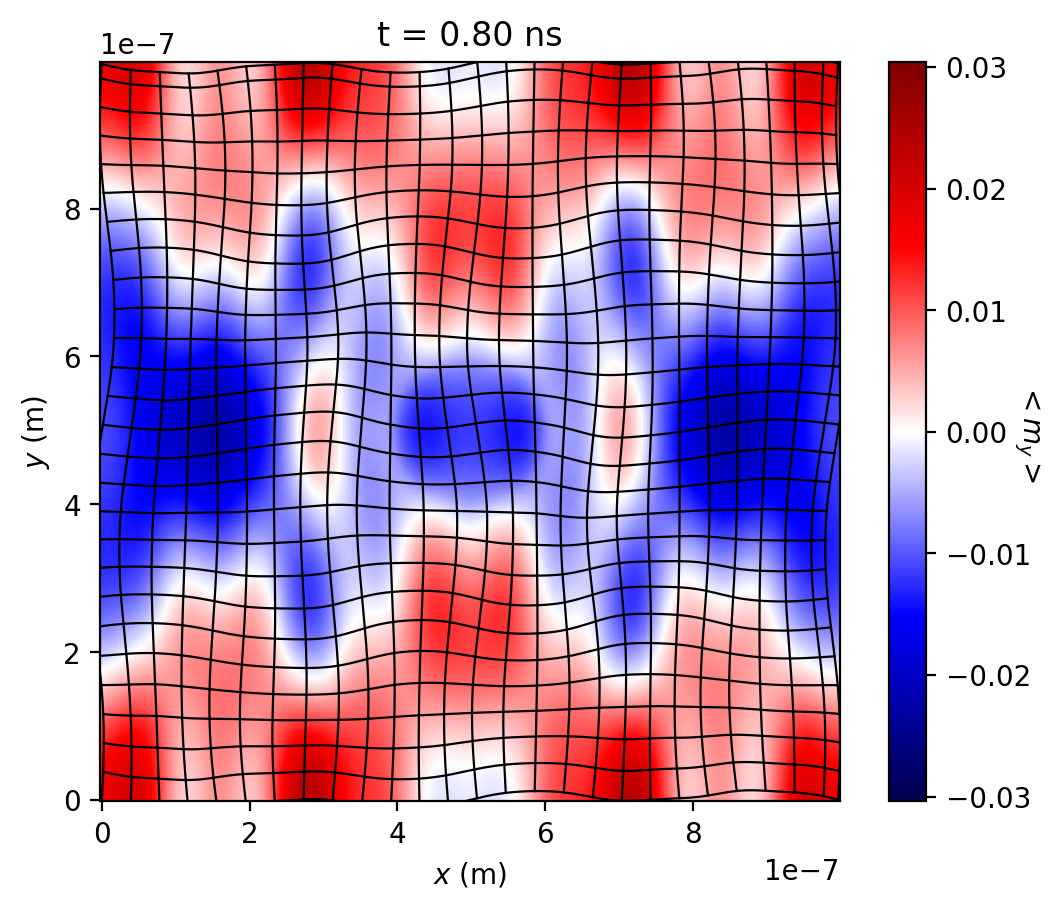

In [3]:
import math

import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from mumaxplus import Ferromagnet, Grid, World
import mumaxplus.util.shape as shapes

plt.rcParams['figure.dpi'] = 200

length, width, thickness = 1e-6, 1e-6, 20e-9
nx, ny, nz = 256, 256, 1
cx, cy, cz = length/nx, width/ny, thickness/nz
cellsize = (cx, cy, cz)

grid = Grid((nx, ny, nz))
world = World(cellsize, mastergrid=Grid((nx, ny, 0)), pbc_repetitions=(2, 2, 0))
magnet = Ferromagnet(world, grid)

magnet.msat = 1.2e6
magnet.aex = 18e-12
magnet.alpha = 0.004
Bdc = 5e-3
magnet.bias_magnetic_field = (Bdc, 0, 0)  # uniform term
magnet.magnetization = (1, 0, 0)

magnet.minimize()

magnet.enable_elastodynamics = True
magnet.rho = 8e3
magnet.B1 = -8.8e6
magnet.B2 = -8.8e6
magnet.C11 = 283e9
magnet.C44 = 58e9
magnet.C12 = 166e9

magnet.elastic_displacement = (0, 0, 0)

# add magnetic field excitation
f_B = 9.8e9
Bac = 1e-3
Bdiam = 200e-9  # excitation diameter

# circular magnetic field excitation at the center
Bshape = shapes.Circle(Bdiam).translate(*magnet.center)
Bmask = magnet._get_mask_array(Bshape, grid, world, "mask")
magnet.bias_magnetic_field.add_time_term(
            lambda t: (0, Bac * math.sin(2*math.pi*f_B * t), 0), mask=Bmask)

magnet.alpha = 0.004
magnet.eta = 1e10  # elastic force damping

# plotting
fig, ax = plt.subplots()

u_scale = 1e5  # amplification of displacement
u_skip  = 10  # don't show every displacement

world.timesolver.adaptive_timestep = False
world.timesolver.timestep = 1e-12

frames = 400
steps_per_frame = 2

# save magnetization and displacement
m = np.zeros(shape=(frames, ny, nx))
u = np.zeros(shape=(frames, *magnet.elastic_displacement.shape))
t = np.zeros(shape=(frames))

# run a simulation
print("Simulating...")
for i in tqdm(range(frames)):
    world.timesolver.steps(steps_per_frame)
    m[i,...] = magnet.magnetization.eval()[1,0,:,:]
    u[i,...] = magnet.elastic_displacement.eval()
    t[i] = world.timesolver.time


# Draw horizontal and vertical lines to connect neighbors
mgrid = magnet.meshgrid
horizontal = []
vertical = []
uxyz = magnet.elastic_displacement.eval()[:,...]
coord = mgrid + uxyz*u_scale
x, y = coord[:2,0,...]

lw = 0.8

for i in range(0, ny, u_skip):  # Iterate over rows
    line = ax.plot(x[i,:], y[i,:], 'k-', lw=lw)  # Horizontal lines
    horizontal.append(line[0])
line = ax.plot(x[-1,:], y[-1,:], 'k-', lw=lw)  # Horizontal lines
horizontal.append(line[0])  # include the last cell to encompass whole grid

for i in range(0, nx, u_skip):  # Iterate over cols
    line = ax.plot(x[:,i], y[:,i], 'k-', lw=lw)  # Vertical lines
    vertical.append(line[0])
line = ax.plot(x[:,-1], y[:,-1], 'k-', lw=lw)  # Vertical lines
vertical.append(line[0])


# imshow setup
im_extent = (-0.5*cx, length - 0.5*cx, -0.5*cy, width - 0.5*cy)
vmax, vmin = np.max(m), np.min(m)
vmax = max(abs(vmax), abs(vmin))
vmin = -vmax
m_im = ax.imshow(m[0,...], origin="lower", extent=im_extent, vmin=vmin, vmax=vmax, cmap="seismic")

# colorbar setup
cbar = plt.colorbar(m_im)
cbar.ax.set_ylabel(r"$<m_y>$", rotation=270)

# final touches
ax.set_xlabel("$x$ (m)")
ax.set_ylabel("$y$ (m)")
ax.set_xlim(im_extent[0], im_extent[1])
ax.set_ylim(im_extent[2], im_extent[3])

def update(i):
    ax.set_title(f"t = {t[i]*1e9:.2f} ns")

    m_im.set_data(m[i,...])

    coord = mgrid + u[i,...]*u_scale
    x,y = coord[:2,0,...]

    # Horizontal lines
    for k, j in enumerate(range(0, ny, u_skip)):
        horizontal[k].set_data(x[j,:], y[j,:])
    horizontal[-1].set_data(x[-1,:], y[-1,:])

    # Vertical lines
    for k, j in enumerate(range(0, nx, u_skip)):
        vertical[k].set_data(x[:,j], y[:,j])
    vertical[-1].set_data(x[:,-1], y[:,-1])

    return m_im, *horizontal, *vertical

# animation
print("Animating...")
animation_fig = animation.FuncAnimation(fig, update, frames=frames, interval=40, blit=True)
animation_fig.save("magnetoelastic.mp4")
print("Done!")